<a href="https://colab.research.google.com/github/IMPERIUMSIXTH/JupyterNotebooks/blob/main/CCC_Hackathon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import polars as plx
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import scipy

In [4]:
import glob
import os

# Find all input text files in the content directory
file_paths = sorted(glob.glob('/content/in_level-1_*.txt'))

# Load and display the content of each file
files_data = {}
for path in file_paths:
    file_name = os.path.basename(path)
    with open(path, 'r', encoding='utf-8') as f:
        content = f.read()
    files_data[file_name] = content
    print(f"=== {file_name} (Length: {len(content)}) ===")
    # Display first 200 characters as a preview
    print(content[:200])
    print("\n" + "="*40 + "\n")

=== in_level-1_0-example.txt (Length: 66) ===
BOP,Temperature [°C],Humidity [%]
1,20,15
2,24,15
3,24,15
4,20,10



=== in_level-1_1-a.txt (Length: 80) ===
BOP,Temperature [°C],Humidity [%]
1,22,72
2,32,39
3,6,77
4,seventeen,89
5,28,42



=== in_level-1_2-b.txt (Length: 489) ===
BOP,Temperature [°C],Humidity [%]
6,37,52
7,10,31
8,18,86
9,19,29
10,39,89
12,43,79
14,29,11
15,17,21
16,26,78
18,16,52
19,33,55
20,0,31
21,24,68
22,36,57
23,5,48
27,9,76
28,15,74
29,-3,68
30,27,22
32


=== in_level-1_3-c.txt (Length: 1949) ===
BOP,Temperature [°C],Humidity [%]
11,37,64
13,10,26
17,17,66
24,39,21
25,33,72
26,29,16
31,18,82
33,18,68
35,36,95
36,19,65
37,36,5
38,19,42
39,27,69
40,18,61
43,24,27
44,10,15
48,27,27
51,5,75
53,26,


=== in_level-1_4-d.txt (Length: 809) ===
BOP,Temperature [°C],Humidity [%]
269,19,33
285,19,58
327,19,35
355,19,7
400,19,76
437,19,34
438,19,32
490,19,17
518,19,71
619,19,48
636,19,36
650,19,51
680,19,74
733,19,26
742,19,51
760,19,67
764,19,


=== in_level-1_5-e.txt (Lengt

In [5]:
!pip install -q pypdf
import pypdf

# Extract text from the level-1.pdf instruction file
pdf_path = '/content/level-1.pdf'
if os.path.exists(pdf_path):
    reader = pypdf.PdfReader(pdf_path)
    print(f"Total Pages: {len(reader.pages)}")
    for idx, page in enumerate(reader.pages):
        print(f"--- PAGE {idx+1} ---")
        print(page.extract_text())
else:
    print("level-1.pdf not found in /content/")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 407.8/407.8 kB 19.3 MB/s eta 0:00:00
Total Pages: 4
--- PAGE 1 ---
CCC Data & AI:
-=: Migratory Birds := -
continue
#WeLoveSoftwareu too? cloudflight.io/career
#WeLoveSoftware
u too? cloudflight.io/career

--- PAGE 2 ---
Level 1
LEVEL 1
LEVEL 1#WeLoveSoftwareu too? cloudflight.io/career
--- PAGE 3 ---
Level 1: The Bird Observation Points
You are ORNITHOLOGISTS, who want to study 
the behavior of some migratory birds across 
different countries.
From Dr. Dr. Wingman, a renowned migratory 
bird expert, you have received a list of bird 
observation points (BOPs), including information 
about their locations.
continue

--- PAGE 4 ---
Level 1: Acceptance Criteria
For the first level to succeed, upload a txt file 
containing the sorted BOPs (separated by spaces).
Sample (included in level_1.zip):
You will surely become a migratory bird expert too. 
That’s it – good luck!
submit
2 3 4 1
Level 1: The Bird Observation Points
continue
• The birds are m

In [11]:
import os
import glob

# Dictionary to convert written number words to floats
WORD_TO_NUM = {
    'zero': 0, 'one': 1, 'two': 2, 'three': 3, 'four': 4, 'five': 5,
    'six': 6, 'seven': 7, 'eight': 8, 'nine': 9, 'ten': 10,
    'eleven': 11, 'twelve': 12, 'thirteen': 13, 'fourteen': 14,
    'fifteen': 15, 'sixteen': 16, 'seventeen': 17, 'eighteen': 18,
    'nineteen': 19, 'twenty': 20
}

def parse_value(val_str):
    val_str = val_str.strip().lower()
    if val_str in WORD_TO_NUM:
        return float(WORD_TO_NUM[val_str])
    return float(val_str)

def clean_and_parse_line(line):
    parts = [p.strip() for p in line.split(',')]
    if len(parts) < 3:
        return None
    try:
        bop = int(parts[0])
        temp = parse_value(parts[1])
        hum = parse_value(parts[2])
        return (bop, temp, hum)
    except (ValueError, KeyError):
        # Skip genuinely malformed lines
        return None

input_files = sorted(glob.glob('/content/in_level-1_*.txt'))

for file_path in input_files:
    filename = os.path.basename(file_path)
    output_filename = filename.replace('in_level-1_', 'out_level-1_')
    output_path = os.path.join('/content', output_filename)

    bops_data = []
    with open(file_path, 'r', encoding='utf-8') as f:
        header = f.readline() # Read header
        for line in f:
            if not line.strip():
                continue
            parsed = clean_and_parse_line(line)
            if parsed is not None:
                bops_data.append(parsed)

    # Sort criteria:
    # 1. Temperature descending (-x[1])
    # 2. Humidity ascending (x[2])
    # 3. BOP ascending (x[0])
    bops_data.sort(key=lambda x: (-x[1], x[2], x[0]))

    # Extract BOP IDs
    sorted_bops = [str(x[0]) for x in bops_data]
    output_content = " ".join(sorted_bops)

    with open(output_path, 'w', encoding='utf-8') as f_out:
        f_out.write(output_content)

    print(f"Processed {filename} -> Saved to {output_filename}")
    print(f"Total items processed: {len(sorted_bops)}")
    print(f"First 10 sorted BOPs: {sorted_bops[:10]}\n")

Processed in_level-1_0-example.txt -> Saved to out_level-1_0-example.txt
Total items processed: 4
First 10 sorted BOPs: ['2', '3', '4', '1']

Processed in_level-1_1-a.txt -> Saved to out_level-1_1-a.txt
Total items processed: 5
First 10 sorted BOPs: ['2', '5', '1', '4', '3']

Processed in_level-1_2-b.txt -> Saved to out_level-1_2-b.txt
Total items processed: 51
First 10 sorted BOPs: ['381', '116', '12', '310', '42', '235', '10', '124', '6', '22']

Processed in_level-1_3-c.txt -> Saved to out_level-1_3-c.txt
Total items processed: 200
First 10 sorted BOPs: ['201', '194', '106', '181', '247', '24', '102', '122', '62', '142']

Processed in_level-1_4-d.txt -> Saved to out_level-1_4-d.txt
Total items processed: 73
First 10 sorted BOPs: ['355', '2125', '2472', '865', '2473', '1067', '2066', '2160', '490', '1810']

Processed in_level-1_5-e.txt -> Saved to out_level-1_5-e.txt
Total items processed: 2171
First 10 sorted BOPs: ['2359', '1944', '1480', '2018', '1647', '1330', '2260', '1509', '535

In [10]:
# Let's inspect the content and any skipped lines in 'in_level-1_1-a.txt' and 'in_level-1_5-e.txt'
for fname in ['in_level-1_1-a.txt', 'in_level-1_5-e.txt']:
    path = os.path.join('/content', fname)
    print(f"--- Inspecting {fname} ---")
    with open(path, 'r', encoding='utf-8') as f:
        lines = f.readlines()
    print(f"Total lines (including header): {len(lines)}")

    skipped = []
    parsed_count = 0
    for i, line in enumerate(lines[1:], start=2):
        if not line.strip():
            continue
        parsed = clean_and_parse_line(line)
        if parsed is None:
            skipped.append((i, line.strip()))
        else:
            parsed_count += 1

    print(f"Successfully parsed: {parsed_count}")
    print(f"Skipped lines ({len(skipped)}): {skipped[:20]}")
    print("\n")

--- Inspecting in_level-1_1-a.txt ---
Total lines (including header): 6
Successfully parsed: 4
Skipped lines (1): [(5, '4,seventeen,89')]


--- Inspecting in_level-1_5-e.txt ---
Total lines (including header): 2172
Successfully parsed: 2170
Skipped lines (1): [(32, '287,seventeen,29')]




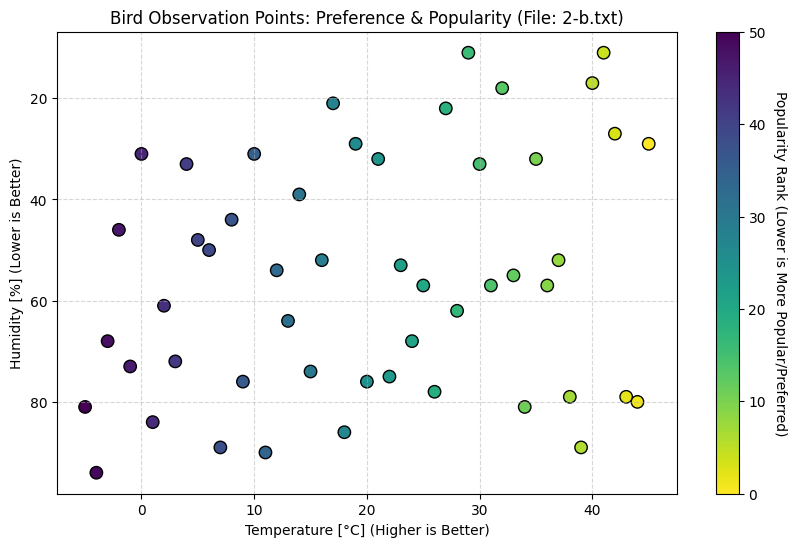

In [7]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Let's plot the distribution and sorted rank for dataset 'in_level-1_2-b.txt' as a representative example
file_to_plot = '/content/in_level-1_2-b.txt'

bops = []
temps = []
hums = []

with open(file_to_plot, 'r', encoding='utf-8') as f:
    f.readline()  # skip header
    for line in f:
        if not line.strip():
            continue
        parsed = clean_and_parse_line(line)
        if parsed is not None:
            bops.append(parsed[0])
            temps.append(parsed[1])
            hums.append(parsed[2])

df_plot = pd.DataFrame({'BOP': bops, 'Temperature': temps, 'Humidity': hums})

# Calculate popularity rank (0 being most popular/preferred)
df_plot['Rank'] = df_plot.apply(lambda row: (-row['Temperature'], row['Humidity'], row['BOP']), axis=1).argsort().argsort()

plt.figure(figsize=(10, 6))
scatter = plt.scatter(df_plot['Temperature'], df_plot['Humidity'], c=df_plot['Rank'], cmap='viridis_r', s=80, edgecolor='k')
cbar = plt.colorbar(scatter)
cbar.set_label('Popularity Rank (Lower is More Popular/Preferred)', rotation=270, labelpad=15)

plt.title('Bird Observation Points: Preference & Popularity (File: 2-b.txt)')
plt.xlabel('Temperature [°C] (Higher is Better)')
plt.ylabel('Humidity [%] (Lower is Better)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.gca().invert_yaxis() # Invert y-axis so visually "lower" humidity is higher up
plt.show()

/tmp/ipykernel_1776/1560784198.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_all, x='Dataset', y='Temperature', ax=axes[0], palette='coolwarm')
/tmp/ipykernel_1776/1560784198.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_all, x='Dataset', y='Humidity', ax=axes[1], palette='Blues')


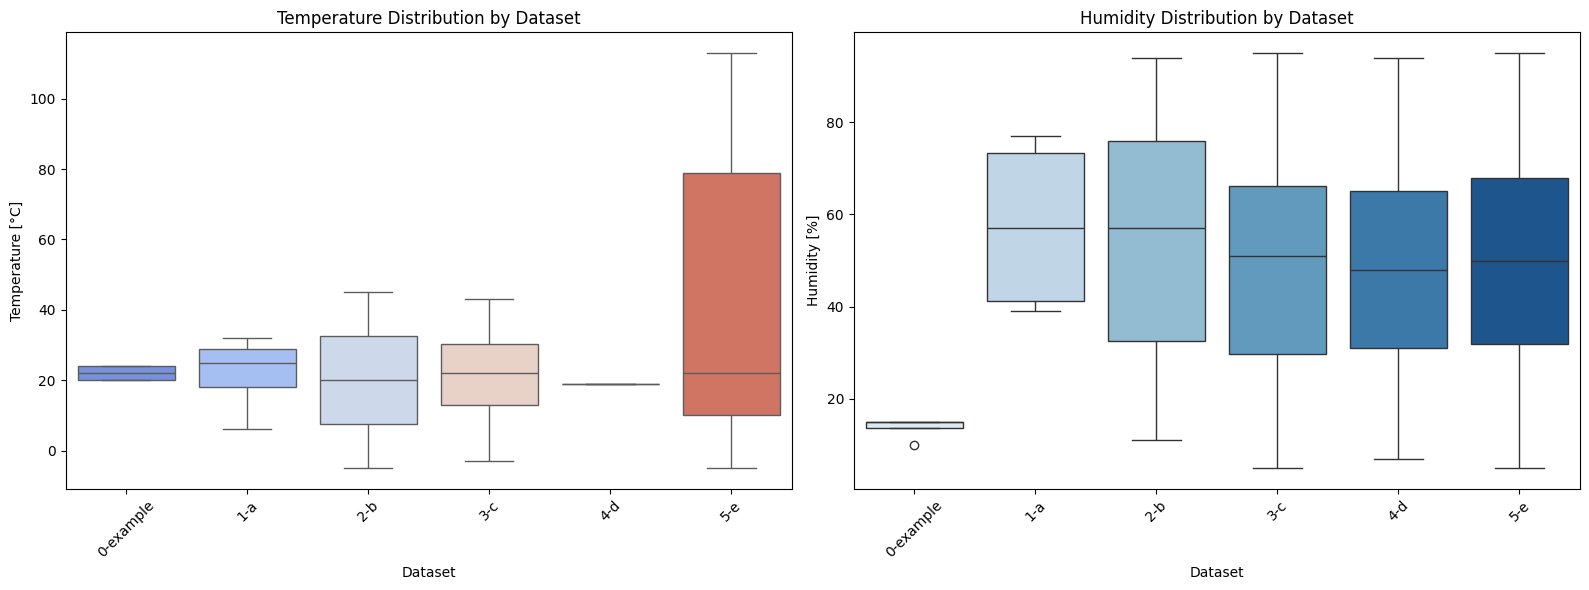

In [8]:
import matplotlib.pyplot as plt
import pandas as pd
import glob
import os

# Gather data from all datasets
all_dfs = []
for file_path in sorted(glob.glob('/content/in_level-1_*.txt')):
    dataset_name = os.path.basename(file_path).replace('in_level-1_', '').replace('.txt', '')
    bops, temps, hums = [], [], []
    with open(file_path, 'r', encoding='utf-8') as f:
        f.readline()
        for line in f:
            if not line.strip():
                continue
            parsed = clean_and_parse_line(line)
            if parsed is not None:
                bops.append(parsed[0])
                temps.append(parsed[1])
                hums.append(parsed[2])
    df_temp = pd.DataFrame({'Dataset': dataset_name, 'Temperature': temps, 'Humidity': hums})
    all_dfs.append(df_temp)

df_all = pd.concat(all_dfs, ignore_index=True)

# Plot distributions
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Temperature Boxplot
sns.boxplot(data=df_all, x='Dataset', y='Temperature', ax=axes[0], palette='coolwarm')
axes[0].set_title('Temperature Distribution by Dataset')
axes[0].set_xlabel('Dataset')
axes[0].set_ylabel('Temperature [°C]')
axes[0].tick_params(axis='x', rotation=45)

# Humidity Boxplot
sns.boxplot(data=df_all, x='Dataset', y='Humidity', ax=axes[1], palette='Blues')
axes[1].set_title('Humidity Distribution by Dataset')
axes[1].set_xlabel('Dataset')
axes[1].set_ylabel('Humidity [%]')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

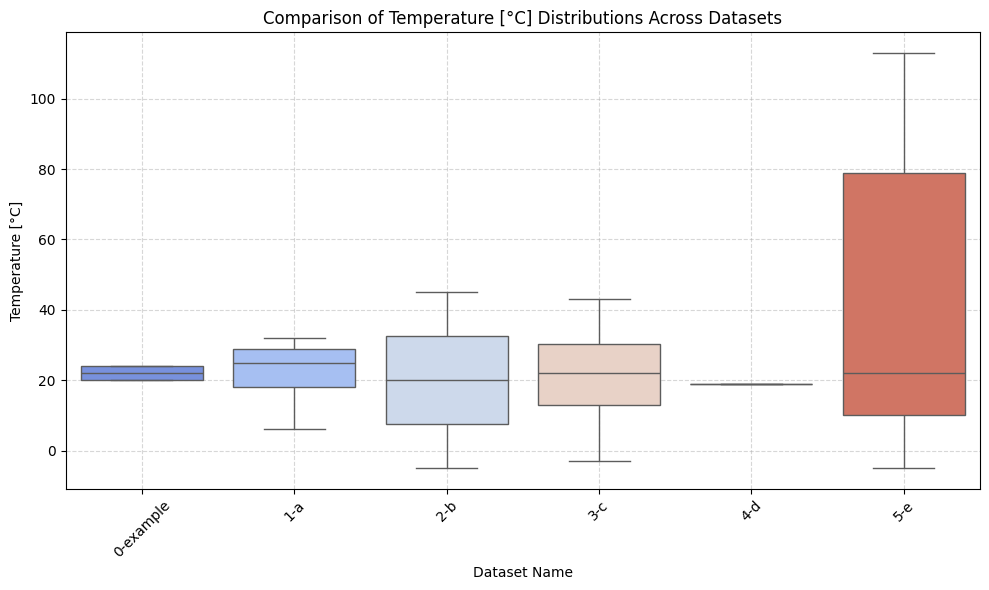

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.boxplot(data=df_all, x='Dataset', y='Temperature', hue='Dataset', palette='coolwarm', legend=False)
plt.title('Comparison of Temperature [°C] Distributions Across Datasets')
plt.xlabel('Dataset Name')
plt.ylabel('Temperature [°C]')
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()